# 06 · Apêndice: a carteira por setor

Separa a carteira do iMOM-BR (residual com filtro) por setor econômico: quanto cada setor pesou, quanto contribuiu para o retorno de cada mês, de cada ano e de cada fatia, e como foi a "subcarteira" de cada setor. Também lista as ações que mais ajudaram e mais atrapalharam em cada ano.

É um apêndice **descritivo**: lê as carteiras do `backtest.pkl` e não muda nenhuma regra, carteira ou número do 01 a 05. Nenhum número daqui serve para escolher parâmetro.

**Como ler a contribuição.** A contribuição de um setor no mês é a soma, entre as ações daquele setor, de peso na carteira × retorno da ação no mês (com a mesma regra de saída da bolsa do 03). Somando os setores, sai exatamente o retorno bruto do iMOM-BR no mês; a primeira conferência trava o notebook se isso não acontecer. A contribuição anual é a soma simples das contribuições mensais, em pontos percentuais (p.p.), e por isso não soma exatamente o retorno composto do ano.

## 1. Parâmetros e carga

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

PASTA = Path('../data/processed')
PASTA_TABELAS = Path('../results/tabelas')
PASTA_SETORES = Path('../results/figuras/setores')
PASTA_SETORES.mkdir(parents=True, exist_ok=True)
RETORNO_AUSENTE = 0.0
MINIMO_MESES_SHARPE = 12
FATIAS = {'treino': ('2020-09-30', '2021-12-31'), 'validacao': ('2022-01-31', '2023-12-31'), 'teste': ('2024-01-31', '2025-12-31')}
FIGURAS_FATIAS = ['validacao', 'teste']

bt = pd.read_pickle(PASTA / 'backtest.pkl')
pesos = bt['pesos']['E_residual_filtro']
serie = bt['series']['E_residual_filtro']['retorno_bruto']
CORTE_SAIDA = bt['parametros']['corte_saida']
retorno = pd.read_pickle(PASTA / 'retorno_mensal.pkl')
saidas = pd.read_pickle(PASTA / 'saidas.pkl')
cadastro = pd.read_pickle(PASTA / 'cadastro_universo.pkl')
cdi = pd.read_pickle(PASTA / 'cdi_mensal.pkl')
ibov = pd.read_pickle(PASTA / 'ibov_mensal.pkl')
elegivel = pd.read_pickle(PASTA / 'elegivel.pkl')
sinal = pd.read_pickle(PASTA / 'sinal_residual.pkl')

setor = cadastro['setor_economico'].reindex(pesos.columns).fillna('Sem setor')
MESES = pesos.index
datas = retorno.index
print('meses de carteira:', len(MESES), MESES[0].date(), 'a', MESES[-1].date(), '| corte de saída:', CORTE_SAIDA)

meses de carteira: 64 2020-09-30 a 2025-12-31 | corte de saída: -0.3


## 2. Retorno de cada ação no mês e contribuição por setor
Mesma regra do 03: a ação da carteira que deixa de ter preço no mês seguinte ao último preço recebe o corte de saída; ausência sem saída recebe zero.

In [2]:
ultimo_com_preco = saidas['ultimo_mes_com_preco']
ret = retorno.reindex(index=MESES, columns=pesos.columns)
for s in MESES:
    anterior = datas[datas.get_loc(s) - 1]
    na_carteira = pesos.loc[s] > 0
    faltou = ret.loc[s].isna() & na_carteira
    saiu = faltou & (ultimo_com_preco.reindex(pesos.columns) == anterior).to_numpy()
    ret.loc[s, saiu[saiu].index] = CORTE_SAIDA
    ret.loc[s, (faltou & ~saiu)[faltou & ~saiu].index] = RETORNO_AUSENTE

contrib_acao = pesos * ret.fillna(0)
contrib = contrib_acao.T.groupby(setor).sum().T
peso_setor = pesos.T.groupby(setor).sum().T
contrib = contrib.loc[:, peso_setor.sum() > 0]
peso_setor = peso_setor.loc[:, contrib.columns]
ordem = peso_setor.mean().sort_values(ascending=False).index
contrib, peso_setor = contrib[ordem], peso_setor[ordem]

diferenca = (contrib.sum(axis=1) - serie.reindex(MESES)).abs().max()
print('diferença máxima entre a soma dos setores e o retorno do iMOM-BR:', diferenca)
assert diferenca < 1e-12
print('setores que aparecem na carteira:', list(ordem))

diferença máxima entre a soma dos setores e o retorno do iMOM-BR: 2.7755575615628914e-17
setores que aparecem na carteira: ['Bens industriais', 'Consumo cíclico', 'Materiais básicos', 'Consumo não cíclico', 'Utilidade pública', 'Petróleo gás e biocombustíveis', 'Saúde', 'Tecnologia da informação', 'Comunicações']


## 3. Peso de cada setor: carteira do iMOM-BR contra o universo
O universo é o das ações elegíveis com sinal na data de decisão, em pesos iguais. A diferença mostra para onde o filtro de qualidade e o sinal inclinaram a carteira.

In [3]:
def fatia_de(m):
    for nome, (a, b) in FATIAS.items():
        if pd.Timestamp(a) <= m <= pd.Timestamp(b):
            return nome

decisao = {m: datas[datas.get_loc(m) - 1] for m in MESES}
candidatas = pd.DataFrame({m: (elegivel.loc[decisao[m]] & sinal.loc[decisao[m]].notna()) for m in MESES}).T.reindex(columns=pesos.columns).fillna(False)
peso_universo = candidatas.div(candidatas.sum(axis=1), axis=0).T.groupby(setor).sum().T.reindex(columns=ordem).fillna(0)

linhas = []
for nome, (a, b) in FATIAS.items():
    linhas.append(pd.DataFrame({'fatia': nome, 'carteira iMOM-BR (%)': peso_setor.loc[a:b].mean() * 100, 'universo (%)': peso_universo.loc[a:b].mean() * 100}))
peso_fatia = pd.concat(linhas).rename_axis('setor').reset_index()
peso_fatia['diferença (p.p.)'] = peso_fatia['carteira iMOM-BR (%)'] - peso_fatia['universo (%)']
peso_fatia = peso_fatia.round(1)
peso_fatia.to_csv(PASTA_TABELAS / '06_peso_por_setor.csv', index=False)
print(peso_fatia.pivot(index='setor', columns='fatia', values='carteira iMOM-BR (%)').reindex(ordem)[list(FATIAS)].to_string())

fatia                           treino  validacao  teste
setor_economico                                         
Bens industriais                  19.9       29.1   26.8
Consumo cíclico                   16.7       10.8   32.3
Materiais básicos                 22.0       27.3   11.1
Consumo não cíclico               16.9       10.6    6.1
Utilidade pública                 10.6        6.8    7.2
Petróleo gás e biocombustíveis     5.7        8.3    7.1
Saúde                              4.4        6.4    9.3
Tecnologia da informação           3.1        0.6    0.0
Comunicações                       0.8        0.0    0.0


## 4. Contribuição por setor: por ano e por fatia
Em pontos percentuais. A última linha é o retorno composto do iMOM-BR no período, para comparar com a soma.

In [4]:
anual = contrib.groupby(contrib.index.year).sum() * 100
anual.loc[:, 'soma dos setores'] = anual.sum(axis=1)
anual.loc[:, 'retorno composto do iMOM-BR'] = serie.reindex(MESES).groupby(MESES.year).apply(lambda r: (1 + r).prod() - 1) * 100
anual.loc[:, 'Ibovespa'] = ibov.reindex(MESES).groupby(MESES.year).apply(lambda r: (1 + r).prod() - 1) * 100
anual.loc[:, 'CDI'] = cdi.reindex(MESES).groupby(MESES.year).apply(lambda r: (1 + r).prod() - 1) * 100
anual = anual.round(1)
anual.rename_axis('ano').to_csv(PASTA_TABELAS / '06_contribuicao_por_ano.csv')

por_fatia = pd.DataFrame({nome: contrib.loc[a:b].sum() * 100 for nome, (a, b) in FATIAS.items()}).round(1)
por_fatia.loc['soma dos setores'] = por_fatia.sum()
por_fatia.rename_axis('setor').to_csv(PASTA_TABELAS / '06_contribuicao_por_fatia.csv')
print(anual.T.to_string())
print()
print(por_fatia.to_string())

                                2020  2021  2022  2023  2024  2025
setor_economico                                                   
Bens industriais                 8.0   4.0   3.0  12.6   5.1   4.8
Consumo cíclico                  1.8  -2.4   5.0   5.9  -5.6  25.8
Materiais básicos                0.9  10.3   0.5   2.4  -2.5   0.4
Consumo não cíclico              0.1  -0.9  -2.2  -2.4  -0.6  -0.1
Utilidade pública                1.7  -0.7   4.0   1.6  -0.9   2.8
Petróleo gás e biocombustíveis   2.2   0.9   1.4   3.4  -0.6   0.7
Saúde                            0.2  -0.3  -0.2   1.3  -0.4   2.1
Tecnologia da informação         0.0  -0.4  -0.9   0.0   0.0   0.0
Comunicações                    -0.1   0.0   0.0   0.0   0.0   0.0
soma dos setores                14.8  10.6  10.7  24.8  -5.6  36.4
retorno composto do iMOM-BR     15.0   8.6   9.2  25.0  -6.2  41.6
Ibovespa                        19.8 -11.9   4.7  22.3 -10.4  34.0
CDI                              0.6   4.4  12.4  13.0  10.9  

## 5. A subcarteira de cada setor
Para cada setor, o retorno do mês da parte da carteira do iMOM-BR que estava naquele setor (média ponderada pelos pesos, só nos meses em que o setor estava na carteira). Mostra se o setor foi bem ou mal **enquanto esteve na carteira**. O Sharpe só é calculado com pelo menos 12 meses de presença. Com poucas ações por setor, os números são muito ruidosos: servem para descrever, não para concluir.

In [5]:
def metricas_setor(a, b):
    linhas = {}
    for st in ordem:
        p = peso_setor.loc[a:b, st]
        presente = p > 0
        r = (contrib.loc[a:b, st][presente] / p[presente])
        ex = r - cdi.reindex(r.index)
        linhas[st] = {'meses na carteira': int(presente.sum()), 'peso médio (%)': p.mean() * 100,
                      'retorno acumulado da subcarteira (%)': ((1 + r).prod() - 1) * 100 if len(r) else np.nan,
                      'volatilidade anual (%)': r.std(ddof=1) * np.sqrt(12) * 100 if len(r) > 1 else np.nan,
                      'Sharpe': ex.mean() / ex.std(ddof=1) * np.sqrt(12) if len(r) >= MINIMO_MESES_SHARPE else np.nan,
                      'contribuição (p.p.)': contrib.loc[a:b, st].sum() * 100,
                      'ações diferentes': int((pesos.loc[a:b, setor[setor == st].index] > 0).any().sum())}
    return pd.DataFrame(linhas).T

tabelas = []
for nome, (a, b) in FATIAS.items():
    t = metricas_setor(a, b).round(2)
    t.insert(0, 'fatia', nome)
    tabelas.append(t)
    print('---', nome)
    print(t.drop(columns='fatia').to_string())
pd.concat(tabelas).rename_axis('setor').to_csv(PASTA_TABELAS / '06_metricas_por_setor.csv')

--- treino
                                meses na carteira  peso médio (%)  retorno acumulado da subcarteira (%)  volatilidade anual (%)  Sharpe  contribuição (p.p.)  ações diferentes
Bens industriais                             16.0           19.91                                 93.80                   34.79    1.50                11.98              12.0
Consumo cíclico                              16.0           16.73                                 -8.45                   21.80   -0.37                -0.63              14.0
Materiais básicos                            13.0           21.99                                 49.95                   34.60    1.12                11.15              13.0
Consumo não cíclico                          16.0           16.88                                  0.19                   20.16   -0.08                -0.74              11.0
Utilidade pública                            16.0           10.60                                 -2.51           

## 6. As ações que mais ajudaram e mais atrapalharam em cada ano
Soma das contribuições mensais de cada ação no ano (peso × retorno), em p.p. É a lista para explicar os choques: qual empresa, de qual setor, puxou a carteira para cima ou para baixo.

In [6]:
ano_acao = contrib_acao.groupby(contrib_acao.index.year).sum() * 100
linhas = []
for ano, linha in ano_acao.iterrows():
    linha = linha[linha != 0]
    for tipo, sel in [('mais ajudou', linha.nlargest(5)), ('mais atrapalhou', linha.nsmallest(5))]:
        for codigo, v in sel.items():
            meses = int((pesos.loc[pesos.index.year == ano, codigo] > 0).sum())
            linhas.append({'ano': ano, 'tipo': tipo, 'ação': codigo, 'setor': setor[codigo], 'contribuição (p.p.)': round(v, 2), 'meses na carteira': meses})
extremos = pd.DataFrame(linhas)
extremos.to_csv(PASTA_TABELAS / '06_acoes_extremas_por_ano.csv', index=False)
for ano in sorted(extremos['ano'].unique()):
    print('---', ano)
    print(extremos[extremos['ano'] == ano].drop(columns='ano').to_string(index=False))

--- 2020
           tipo  ação                          setor  contribuição (p.p.)  meses na carteira
    mais ajudou ETER3               Bens industriais                 5.19                  4
    mais ajudou PRIO3 Petróleo gás e biocombustíveis                 2.86                  4
    mais ajudou RAPT4               Bens industriais                 1.74                  4
    mais ajudou AXIA3              Utilidade pública                 0.79                  2
    mais ajudou SMTO3            Consumo não cíclico                 0.69                  4
mais atrapalhou BEEF3            Consumo não cíclico                -0.89                  3
mais atrapalhou MBRF3            Consumo não cíclico                -0.74                  4
mais atrapalhou LAME4                Consumo cíclico                -0.70                  4
mais atrapalhou ENAT3 Petróleo gás e biocombustíveis                -0.64                  2
mais atrapalhou KEPL3               Bens industriais         

## 7. Figuras
Cores no padrão do layout da apresentação (roxos e cinzas). Para ficar legível, os 6 setores que mais pesam na carteira no período inteiro aparecem com cor própria e os demais são somados em "Outros". Duas figuras do período inteiro (peso por setor mês a mês; contribuição de cada setor para o retorno de cada ano, em barras empilhadas, com o retorno do iMOM-BR e do Ibovespa no ano), um mapa de calor com os mesmos números da contribuição anual e uma figura por fatia liberada (contribuição acumulada mês a mês). Pasta `results/figuras/setores/`.

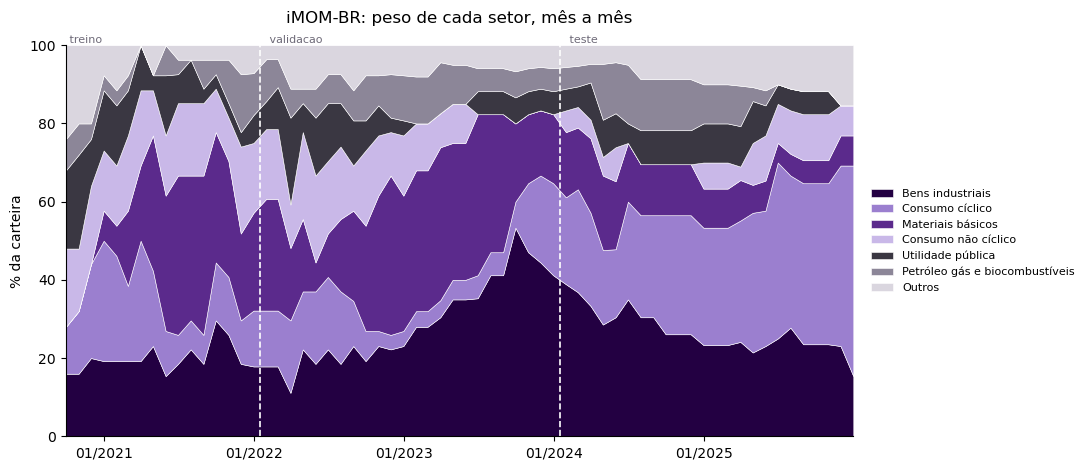

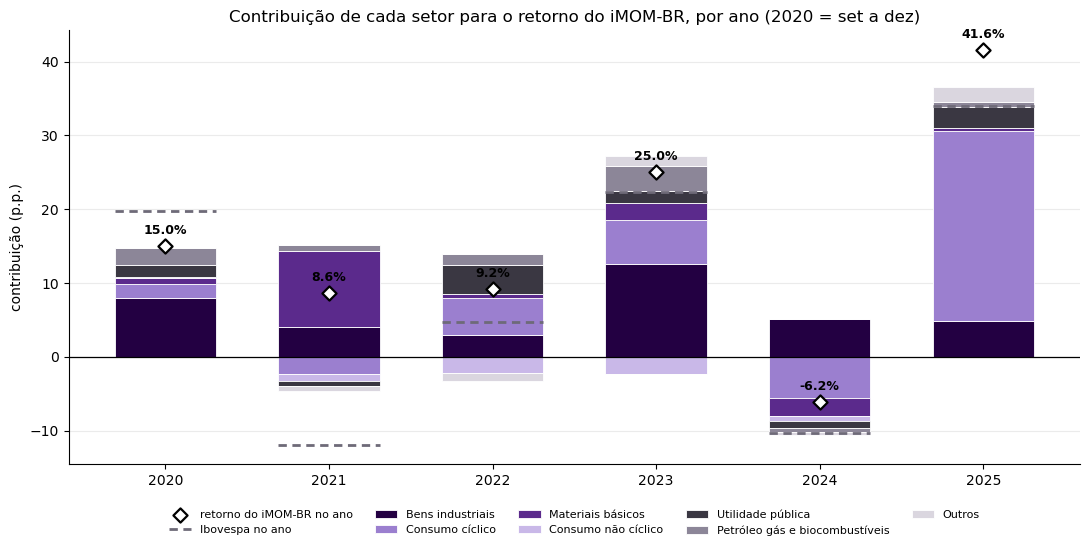

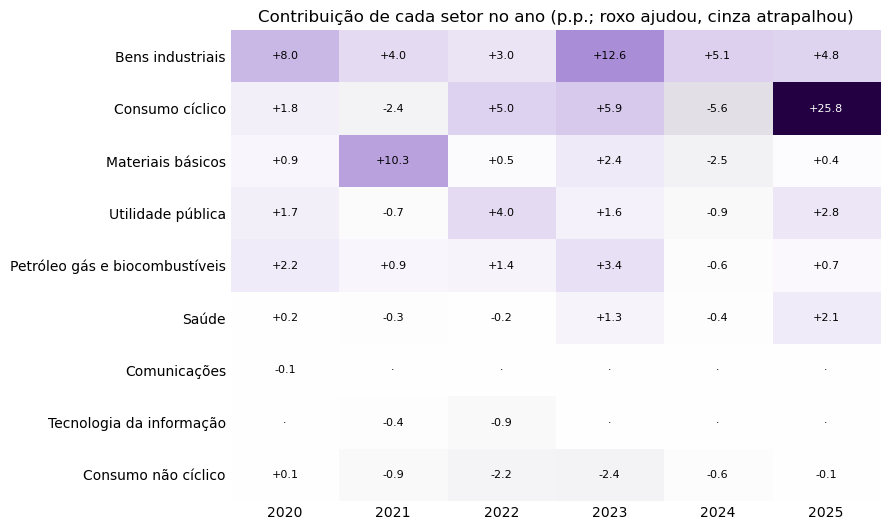

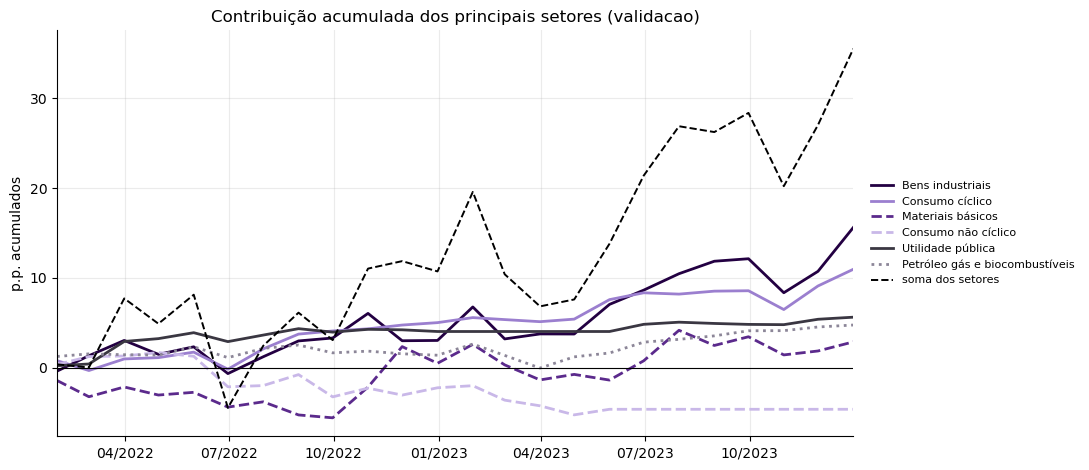

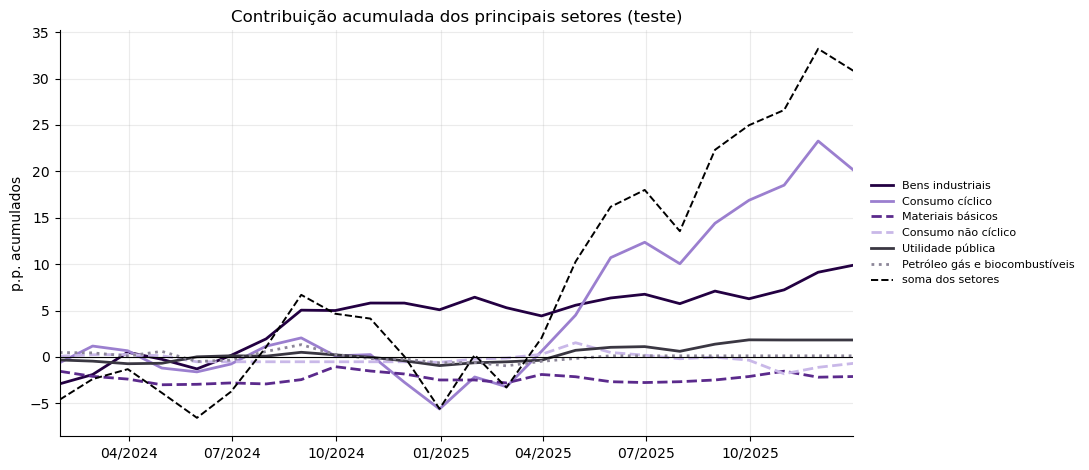

In [7]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

ROXO_ESCURO, CINZA, CINZA_CLARO, LILAS = '#230042', '#6E6A78', '#A8A3B3', '#A88BD6'
TONS = ['#230042', '#9B7FCF', '#5B2A8C', '#C9B8E8', '#3A3742', '#8C8698']
COR_OUTROS = '#DAD6DF'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

N_PRINCIPAIS = 6
principais = list(ordem[:N_PRINCIPAIS])
COR = {st: TONS[i] for i, st in enumerate(principais)} | {'Outros': COR_OUTROS}
GRUPOS = principais + ['Outros']


def agrupar(tabela):
    t = tabela.reindex(columns=ordem).fillna(0.0)
    return pd.concat([t[principais], t.drop(columns=principais).sum(axis=1).rename('Outros')], axis=1)


def marcar_fatias(ax):
    for nome, (a, b) in FATIAS.items():
        ax.axvline(pd.Timestamp(a) - pd.Timedelta(days=15), color='white', lw=1.2, ls='--')
        ax.text(pd.Timestamp(a), ax.get_ylim()[1], ' ' + nome, va='bottom', fontsize=8, color=CINZA)


# 06_01: peso de cada setor, mês a mês
peso = agrupar(peso_setor) * 100
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.stackplot(peso.index, peso.T.to_numpy(), labels=GRUPOS, colors=[COR[g] for g in GRUPOS], edgecolor='white', linewidth=0.4)
ax.set_ylabel('% da carteira'); ax.set_ylim(0, 100); ax.set_title('iMOM-BR: peso de cada setor, mês a mês', pad=16)
ax.set_xlim(MESES[0], MESES[-1]); ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y')); marcar_fatias(ax)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(PASTA_SETORES / '06_01_peso_por_setor.png', dpi=200); plt.show()

# 06_02: contribuição de cada setor para o retorno de cada ano (barras empilhadas)
contrib_ano = agrupar(anual[ordem])
anos = contrib_ano.index.astype(str)
x = np.arange(len(anos))
fig, ax = plt.subplots(figsize=(11, 5.6))
base_pos = np.zeros(len(anos)); base_neg = np.zeros(len(anos))
for g in GRUPOS:
    v = contrib_ano[g].to_numpy()
    pos, neg = np.where(v > 0, v, 0), np.where(v < 0, v, 0)
    ax.bar(x, pos, 0.62, bottom=base_pos, color=COR[g], edgecolor='white', linewidth=0.6, label=g)
    ax.bar(x, neg, 0.62, bottom=base_neg, color=COR[g], edgecolor='white', linewidth=0.6)
    base_pos += pos; base_neg += neg
total = anual['retorno composto do iMOM-BR'].to_numpy(); ibov_ano = anual['Ibovespa'].to_numpy()
ax.scatter(x, total, marker='D', s=52, facecolor='white', edgecolor='black', linewidth=1.6, zorder=5, label='retorno do iMOM-BR no ano')
ax.hlines(ibov_ano, x - 0.31, x + 0.31, color=CINZA, lw=2, ls=(0, (3, 2)), zorder=4, label='Ibovespa no ano')
for xi, v in zip(x, total):
    ax.annotate(f'{v:.1f}%', (xi, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=9, fontweight='bold')
ax.axhline(0, color='black', lw=0.9)
ax.set_xticks(x, anos); ax.set_ylabel('contribuição (p.p.)')
ax.grid(axis='y', alpha=0.25); ax.set_axisbelow(True)
ax.set_title('Contribuição de cada setor para o retorno do iMOM-BR, por ano (2020 = set a dez)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=5, frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(PASTA_SETORES / '06_02_contribuicao_por_ano.png', dpi=200); plt.show()

# 06_04: os mesmos números da contribuição anual em mapa de calor
mapa = anual[ordem].loc[:, anual[ordem].abs().sum() > 0]
mapa = mapa[mapa.sum().sort_values(ascending=False).index].T
lim = np.nanmax(np.abs(mapa.to_numpy()))
DIVERGENTE = LinearSegmentedColormap.from_list('cinza_roxo', ['#3A3742', '#BDB8C6', '#FFFFFF', LILAS, ROXO_ESCURO])
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.imshow(mapa.to_numpy(), cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -lim, lim), aspect='auto')
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iat[i, j]
        ax.text(j, i, '·' if abs(v) < 0.05 else f'{v:+.1f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.55 * lim else 'black')
ax.set_xticks(range(mapa.shape[1]), mapa.columns.astype(str)); ax.set_yticks(range(mapa.shape[0]), mapa.index)
for lado in ['top', 'right', 'left', 'bottom']: ax.spines[lado].set_visible(False)
ax.tick_params(length=0)
ax.set_title('Contribuição de cada setor no ano (p.p.; roxo ajudou, cinza atrapalhou)')
fig.tight_layout(); fig.savefig(PASTA_SETORES / '06_04_mapa_contribuicao.png', dpi=200); plt.show()

# 06_<fatia>_03: contribuição acumulada mês a mês
TRACOS = ['-', '-', '--', '--', '-', ':']
for nome in FIGURAS_FATIAS:
    a, b = FATIAS[nome]
    acum = agrupar(contrib.loc[a:b]).cumsum() * 100
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for k, g in enumerate(principais):
        ax.plot(acum.index, acum[g], color=COR[g], lw=2, ls=TRACOS[k], label=g)
    ax.plot(acum.index, acum.sum(axis=1), color='black', lw=1.4, ls='--', label='soma dos setores')
    ax.axhline(0, color='black', lw=0.8); ax.set_ylabel('p.p. acumulados'); ax.grid(alpha=0.25)
    ax.set_xlim(acum.index[0], acum.index[-1]); ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
    ax.set_title(f'Contribuição acumulada dos principais setores ({nome})')
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(PASTA_SETORES / f'06_{nome}_03_contribuicao_acumulada.png', dpi=200); plt.show()

## Resumo e limitações

**O que o 06 entrega:** `06_peso_por_setor.csv`, `06_contribuicao_por_ano.csv`, `06_contribuicao_por_fatia.csv`, `06_metricas_por_setor.csv` e `06_acoes_extremas_por_ano.csv` em `results/tabelas`, e as figuras em `results/figuras/setores/` (06_01 peso, 06_02 contribuição por ano, 06_04 mapa de calor e 06_<fatia>_03 contribuição acumulada).

**Limitações:** a contribuição é aritmética (soma de peso × retorno), por isso a soma do ano não é igual ao retorno composto; as subcarteiras por setor têm poucas ações e poucos meses, então volatilidade e Sharpe por setor são muito ruidosos; o setor é o do cadastro atual da Economática; a explicação econômica de cada choque (juros, preços, eventos de empresa) não sai do código: precisa ser escrita no paper com fonte; nenhum número daqui muda a estratégia, e pesar mais um setor por causa deste apêndice seria uma regra nova, escolhida depois de ver os resultados.